In [3]:
!unzip /content/lfw-deepfunneled.zip

A saída de streaming foi truncada nas últimas 5000 linhas.
  inflating: lfw-deepfunneled/lfw-deepfunneled/Pak_Gil_Yon/Pak_Gil_Yon_0001.jpg  
   creating: lfw-deepfunneled/lfw-deepfunneled/Pamela_Anderson/
  inflating: lfw-deepfunneled/lfw-deepfunneled/Pamela_Anderson/Pamela_Anderson_0001.jpg  
  inflating: lfw-deepfunneled/lfw-deepfunneled/Pamela_Anderson/Pamela_Anderson_0002.jpg  
  inflating: lfw-deepfunneled/lfw-deepfunneled/Pamela_Anderson/Pamela_Anderson_0003.jpg  
  inflating: lfw-deepfunneled/lfw-deepfunneled/Pamela_Anderson/Pamela_Anderson_0004.jpg  
  inflating: lfw-deepfunneled/lfw-deepfunneled/Pamela_Anderson/Pamela_Anderson_0005.jpg  
   creating: lfw-deepfunneled/lfw-deepfunneled/Pamela_Melroy/
  inflating: lfw-deepfunneled/lfw-deepfunneled/Pamela_Melroy/Pamela_Melroy_0001.jpg  
   creating: lfw-deepfunneled/lfw-deepfunneled/Paola_Espinoza/
  inflating: lfw-deepfunneled/lfw-deepfunneled/Paola_Espinoza/Paola_Espinoza_0001.jpg  
   creating: lfw-deepfunneled/lfw-deepfunneled

# Prova - Classificador supervisionado


### 1) Qual a base escolhida?

The Labeled Faces in the Wild face recognition dataset - http://vis-www.cs.umass.edu/lfw/

### 2) **(10%)** Pré-processamento: entendimento do conjunto de dados
- **Quais são minhas features?**

As features do conjunto de dados são representadas pelos pixels das imagens. As imagens possuem resolução de 250 × 250 pixels, estão no formato RGB logo possuem 3 canais de cor (vermelho, verde e azul).
Dessa forma, cada imagem possui 250 × 250 × 3 = 187.500 valores numéricos que podem ser utilizados como características de entrada para um modelo de Machine Learning.

- **Quais são minhas classes?**

As classes do conjunto de dados correspondem às diferentes pessoas identificadas. O conjunto de dados possui 5.749 classes diferentes, ou seja, 5.749 pessoas identificadas.

- **Como estão distribuidas minhas classes?**

As classes apresentam uma distribuição bastante desbalanceada. No conjunto de dados existem 5.749 classes (pessoas), com quantidades diferentes de imagens para cada classe. A classe com maior quantidade possui 530 imagens, enquanto algumas classes possuem apenas 1 imagem. A média é de aproximadamente 2,30 imagens por classe, porém a mediana é igual a 1 imagem.
Além disso, 4.069 das 5.749 classes possuem somente uma imagem, correspondendo a aproximadamente 70,8% das classes. Portanto, as classes não estão distribuídas de maneira uniforme, existindo uma grande diferença na quantidade de imagens disponíveis para cada pessoa.

- **Checagem se os valores estão dentro de um limite permitido ou razoável.**

Foi realizada uma verificação dos valores dos pixels em todas as 13.233 imagens do conjunto de dados. As imagens utilizam pixels do tipo uint8, cujo intervalo válido é de 0 a 255. Na análise, o menor valor encontrado foi 0 e o maior valor encontrado foi 255. Nenhuma das 13.233 imagens apresentou valores de pixels fora do intervalo permitido. Portanto, os valores dos pixels estão dentro de limites válidos e razoáveis para imagens RGB, não sendo necessário realizar tratamento para valores de pixels fora do intervalo.

- **Tratamento de valores ausentes por eliminação ou substituição.**

Foi realizada a verificação de valores ausentes no DataFrame utilizando a função isnull(). O resultado mostrou que não existem valores ausentes nas

colunas analisadas:
name: 0 valores ausentes;
image_path: 0 valores ausentes.

Dessa forma, não foi necessário realizar eliminação ou substituição de valores ausentes. Todos os registros possuem as informações necessárias para identificar a pessoa e localizar a respectiva imagem.

- **Conversão do tipo de dados.**

As imagens originalmente possuem pixels armazenados no tipo uint8, com valores entre 0 e 255. Para preparar os dados para utilização em algoritmos de Machine Learning, os pixels foram convertidos para o tipo float32. Em seguida, os valores foram normalizados dividindo cada pixel por 255, fazendo com que os valores passassem do intervalo de 0 a 255 para o intervalo de 0 a 1. Antes da conversão, o tipo dos pixels era uint8. Após a conversão, passou a ser float32. Depois da normalização, o menor valor encontrado foi 0,0 e o maior foi 1,0. Essa transformação facilita o processamento numérico dos dados e coloca os valores dos pixels em uma escala padronizada.


In [21]:
# ============================================================
# 1. IMPORTAÇÃO DAS BIBLIOTECAS
# ============================================================

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from pathlib import Path
from PIL import Image

In [22]:
# ============================================================
# 2. LEITURA DAS IMAGENS
# ============================================================

pasta_imagens = Path("/content/lfw-deepfunneled")
if not pasta_imagens.exists():
    raise FileNotFoundError(
        f"Pasta de imagens não encontrada: {pasta_imagens}"
    )
dados = [
    {
        "name": imagem.parent.name,
        "image_path": str(imagem.resolve()),
    }
    for imagem in pasta_imagens.rglob("*.jpg")
]
df_imagens = pd.DataFrame(dados)
print(df_imagens.head())

           name                                         image_path
0      Sam_Bith  /content/lfw-deepfunneled/lfw-deepfunneled/Sam...
1      Sam_Bith  /content/lfw-deepfunneled/lfw-deepfunneled/Sam...
2      Sam_Bith  /content/lfw-deepfunneled/lfw-deepfunneled/Sam...
3  Frank_Coraci  /content/lfw-deepfunneled/lfw-deepfunneled/Fra...
4   Hugh_Miller  /content/lfw-deepfunneled/lfw-deepfunneled/Hug...


In [23]:
# ============================================================
# 3. DIMENSÕES DO DATASET
# ============================================================

print("Total de imagens:", len(df_imagens))
print("Total de classes:", df_imagens["name"].nunique())
print("Dimensões do DataFrame:", df_imagens.shape)

Total de imagens: 13233
Total de classes: 5749
Dimensões do DataFrame: (13233, 2)


In [24]:
# ============================================================
# 4. CLASSES
# ============================================================

classes = df_imagens["name"].unique()

print("Quantidade de classes:", len(classes))
print("\nPrimeiras classes:")
print(classes[:20])

Quantidade de classes: 5749

Primeiras classes:
['Sam_Bith' 'Frank_Coraci' 'Hugh_Miller' 'Joe_Mantegna' 'Michael_Keaton'
 'Hilmi_Akin_Zorlu' 'Fran_Drescher' 'Gorden_Tallis' 'Juergen_Chrobog'
 'Blythe_Hartley' 'Maggie_Smith' 'Marlon_Devonish' 'Donald_Trump'
 'Ken_Watanabe' 'Aishwarya_Rai' 'Lucia_Kenny_Anthony' 'Joan_Jett'
 'Ira_Einhorn' 'Caroline_Dhavernas' 'Angela_Bassett']


In [25]:
# ============================================================
# 5. DISTRIBUIÇÃO DAS CLASSES
# ============================================================

distribuicao = df_imagens["name"].value_counts()

print("Maior número de imagens em uma classe:",
      distribuicao.max())
print("Menor número de imagens em uma classe:",
      distribuicao.min())
print("Média de imagens por classe:",
      distribuicao.mean())
print("Mediana de imagens por classe:",
      distribuicao.median())
print("\nClasses com apenas uma imagem:",
      (distribuicao == 1).sum())
print("\n20 classes mais frequentes:")
print(distribuicao.head(20))

Maior número de imagens em uma classe: 530
Menor número de imagens em uma classe: 1
Média de imagens por classe: 2.301791615933206
Mediana de imagens por classe: 1.0

Classes com apenas uma imagem: 4069

20 classes mais frequentes:
name
George_W_Bush                530
Colin_Powell                 236
Tony_Blair                   144
Donald_Rumsfeld              121
Gerhard_Schroeder            109
Ariel_Sharon                  77
Hugo_Chavez                   71
Junichiro_Koizumi             60
Jean_Chretien                 55
John_Ashcroft                 53
Serena_Williams               52
Jacques_Chirac                52
Vladimir_Putin                49
Luiz_Inacio_Lula_da_Silva     48
Gloria_Macapagal_Arroyo       44
Jennifer_Capriati             42
Arnold_Schwarzenegger         42
Lleyton_Hewitt                41
Laura_Bush                    41
Hans_Blix                     39
Name: count, dtype: int64


* Gráfico da distribuição das classes:


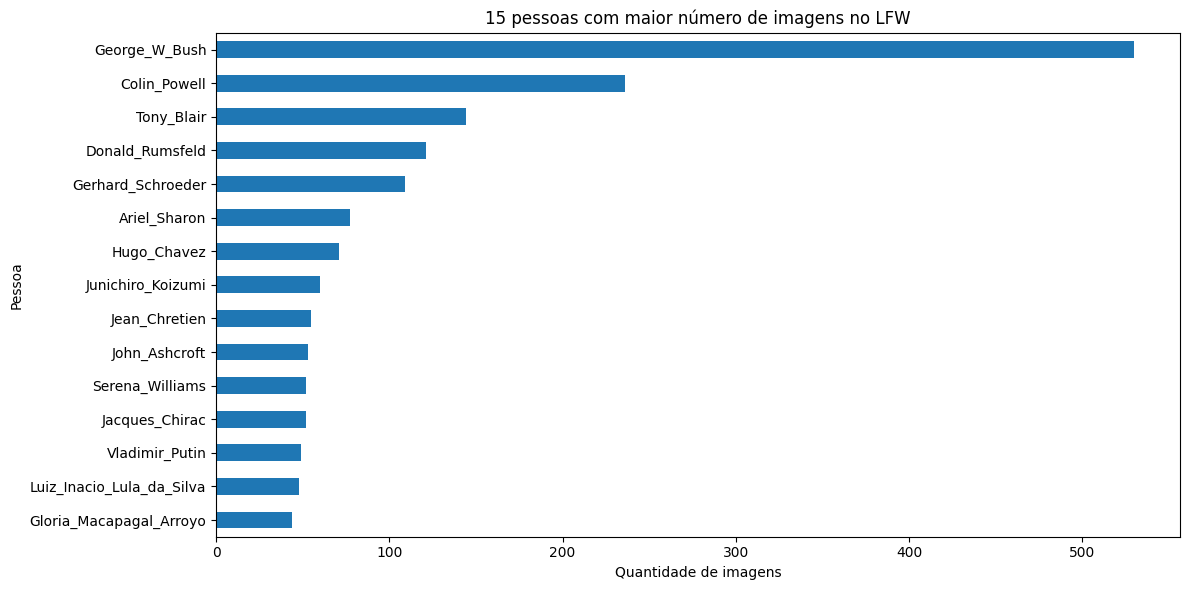

In [26]:
# ============================================================
# 5.1 - GRÁFICO DA DISTRIBUIÇÃO DAS CLASSES
# ============================================================
print("* Gráfico da distribuição das classes:")
# Seleciona as 15 pessoas com maior número de imagens
top_classes = distribuicao.head(15)

plt.figure(figsize=(12, 6))

top_classes.sort_values().plot(
    kind="barh"
)

plt.title("15 pessoas com maior número de imagens no LFW")
plt.xlabel("Quantidade de imagens")
plt.ylabel("Pessoa")
plt.tight_layout()
plt.show()


In [27]:
# ============================================================
# 6. CARACTERÍSTICAS DAS IMAGENS
# ============================================================

caminho = df_imagens.iloc[0]["image_path"]

imagem = Image.open(caminho)
imagem_array = np.array(imagem)

print("Arquivo:", caminho)
print("Tamanho:", imagem.size)
print("Modo:", imagem.mode)
print("Formato:", imagem.format)
print("Shape:", imagem_array.shape)
print("Tipo:", imagem_array.dtype)
print("Pixel mínimo:", imagem_array.min())
print("Pixel máximo:", imagem_array.max())

Arquivo: /content/lfw-deepfunneled/lfw-deepfunneled/Sam_Bith/Sam_Bith_0002.jpg
Tamanho: (250, 250)
Modo: RGB
Formato: JPEG
Shape: (250, 250, 3)
Tipo: uint8
Pixel mínimo: 0
Pixel máximo: 255


In [28]:
# ============================================================
# 7. VERIFICAÇÃO DAS IMAGENS
# ============================================================

dimensoes = {}
modos = {}
erros = []

for caminho in df_imagens["image_path"]:
    try:
        with Image.open(caminho) as img:
            dimensoes[img.size] = dimensoes.get(img.size, 0) + 1
            modos[img.mode] = modos.get(img.mode, 0) + 1
    except Exception as e:
        erros.append((caminho, str(e)))

print("Dimensões:")
print(dimensoes)
print("\nModos:")
print(modos)
print("\nImagens com erro:", len(erros))

Dimensões:
{(250, 250): 13233}

Modos:
{'RGB': 13233}

Imagens com erro: 0


In [29]:
# ============================================================
# 8. CHECAGEM DOS VALORES DOS PIXELS
# ============================================================

pixel_min_global = 255
pixel_max_global = 0
imagens_verificadas = 0
imagens_com_valor_fora = 0

for caminho in df_imagens["image_path"]:
    imagem = Image.open(caminho)
    imagem_array = np.array(imagem)

    pixel_min = imagem_array.min()
    pixel_max = imagem_array.max()

    pixel_min_global = min(pixel_min_global, pixel_min)
    pixel_max_global = max(pixel_max_global, pixel_max)

    if pixel_min < 0 or pixel_max > 255:
        imagens_com_valor_fora += 1

    imagens_verificadas += 1

print("Imagens verificadas:", imagens_verificadas)
print("Menor valor de pixel encontrado:", pixel_min_global)
print("Maior valor de pixel encontrado:", pixel_max_global)
print("Imagens com valores fora do intervalo 0-255:",
      imagens_com_valor_fora)

Imagens verificadas: 13233
Menor valor de pixel encontrado: 0
Maior valor de pixel encontrado: 255
Imagens com valores fora do intervalo 0-255: 0


In [30]:
# ============================================================
# 9. VALORES AUSENTES
# ============================================================

print("Valores ausentes no DataFrame:")
print(df_imagens.isnull().sum())

Valores ausentes no DataFrame:
name          0
image_path    0
dtype: int64


In [31]:
# ============================================================
# 10. CONVERSÃO DO TIPO DE DADOS
# ============================================================

imagem_float = imagem_array.astype(np.float32)
imagem_normalizada = imagem_float / 255.0

print("Tipo original:", imagem_array.dtype)
print("Tipo convertido:", imagem_float.dtype)

print("\nAntes da normalização:")
print("Mínimo:", imagem_float.min())
print("Máximo:", imagem_float.max())

print("\nDepois da normalização:")
print("Mínimo:", imagem_normalizada.min())
print("Máximo:", imagem_normalizada.max())

Tipo original: uint8
Tipo convertido: float32

Antes da normalização:
Mínimo: 0.0
Máximo: 255.0

Depois da normalização:
Mínimo: 0.0
Máximo: 1.0


In [32]:
# ============================================================
# 11. PREPARAÇÃO DOS DADOS PARA CLASSIFICAÇÃO
# ============================================================

X = []
y = []

for _, linha in df_imagens.iterrows():

    imagem = Image.open(linha["image_path"]).convert("RGB")

    imagem = imagem.resize((64, 64))

    imagem_array = np.array(imagem, dtype=np.float32)

    imagem_array = imagem_array / 255.0

    imagem_vetor = imagem_array.flatten()

    X.append(imagem_vetor)

    y.append(linha["name"])

X = np.array(X, dtype=np.float32)
y = np.array(y)

# ============================================================
# VERIFICAÇÃO DOS DADOS
# ============================================================

print("Shape de X:", X.shape)
print("Shape de y:", y.shape)
print("Tipo de X:", X.dtype)
print("Número de classes:", len(np.unique(y)))

Shape de X: (13233, 12288)
Shape de y: (13233,)
Tipo de X: float32
Número de classes: 5749


### 3) **(80%)** Nos blocos seguintes implemente seus classificadores (serão implementados 2 métodos diferentes).

#### 3.1) Qual método escolhido?

Serão usados os métodos: **KNN** e **SVM**. Abaixo seguem os procedimentos com o **KNN**.

#### 3.2) **(10%)** Baseline - Implemente seu classificador da forma mais simples possível para esse ser seu baseline

In [33]:
# ============================================================
# 3.2.1 - FILTRO DE CLASSES E SEPARAÇÃO TREINO/TESTE
# ============================================================
MIN_IMAGENS = 20

contagem = pd.Series(y).value_counts()
classes_validas = contagem[contagem >= MIN_IMAGENS].index
mask = np.isin(y, classes_validas)

X_f, y_f = X[mask], y[mask]

print("Imagens antes do filtro:", len(y))
print("Imagens após o filtro:", len(y_f))
print("Classes após o filtro:", len(classes_validas))

X_train, X_test, y_train, y_test = train_test_split(
    X_f, y_f,
    test_size=0.2,
    random_state=42,
    stratify=y_f
)

print("Dados de treinamento:", X_train.shape)
print("Dados de teste:", X_test.shape)

Imagens antes do filtro: 13233
Imagens após o filtro: 3023
Classes após o filtro: 62
Dados de treinamento: (2418, 12288)
Dados de teste: (605, 12288)


Como o conjunto original possui 5.749 classes e a maioria delas tem apenas uma imagem (4.069 classes, cerca de 70,8%), não é possível treinar e avaliar um classificador de forma confiável com todas elas. Por isso, foram mantidas apenas as pessoas com pelo menos 20 imagens. Após esse filtro, o conjunto passou de 13.233 para 3.023 imagens, distribuídas em 62 classes.

As imagens foram redimensionadas para 64×64 pixels, convertidas para float32 e normalizadas entre 0 e 1, resultando em vetores de 12.288 características. Os dados foram divididos em 80% para treinamento (2.418 imagens) e 20% para teste (605 imagens), com estratificação por classe (stratify) para manter a proporção de cada pessoa nos dois conjuntos.

In [34]:
# ============================================================
# 3.2.2 - KNN BASELINE
# ============================================================
from sklearn.neighbors import KNeighborsClassifier

knn_baseline = KNeighborsClassifier()
knn_baseline.fit(X_train, y_train)
y_pred = knn_baseline.predict(X_test)
accuracy_baseline = accuracy_score(y_test, y_pred)

print(f"Acurácia do KNN Baseline: {accuracy_baseline:.4f}")

Acurácia do KNN Baseline: 0.2083


Foi utilizado o algoritmo K-Nearest Neighbors (KNN) com os parâmetros padrão (K = 5, distância euclidiana e pesos uniformes), aplicado diretamente sobre os pixels. O modelo obteve acurácia de aproximadamente 20,83% no conjunto de teste. Considerando que existem 62 classes (um chute aleatório acertaria cerca de 1,6%), o resultado já é bem superior ao acaso, mas ainda baixo, pois comparar pixels brutos é sensível a variações de iluminação, pose e expressão.

#### 3.3) **(20%)** Versão 1 - O que podemos fazer para melhorar nosso baseline? Aplique técnicas como redução de dimensionalidade, normalização ou outras. Compare os resultados.

In [35]:
# ============================================================
# 3.3.1 - REDUÇÃO DE DIMENSIONALIDADE COM PCA
# ============================================================
from sklearn.decomposition import PCA

pca = PCA(n_components=150, svd_solver="randomized", random_state=42)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Dimensões originais:", X_train.shape)
print("Dimensões após PCA:", X_train_pca.shape)
print("Variância preservada:", pca.explained_variance_ratio_.sum())

Dimensões originais: (2418, 12288)
Dimensões após PCA: (2418, 150)
Variância preservada: 0.88209105


In [36]:
# ============================================================
# 3.3.2 - KNN COM PCA
# ============================================================
knn_pca = KNeighborsClassifier()
knn_pca.fit(X_train_pca, y_train)
y_pred_pca = knn_pca.predict(X_test_pca)
accuracy_pca = accuracy_score(y_test, y_pred_pca)

print(f"Acurácia do KNN com PCA: {accuracy_pca:.4f}")

Acurácia do KNN com PCA: 0.2050


Para melhorar o desempenho do classificador KNN, foi aplicada inicialmente a técnica de redução de dimensionalidade PCA (Principal Component Analysis), mantendo 150 componentes principais, que preservaram aproximadamente 88,2% da variância dos dados. Essa técnica reduziu o número de características de cada imagem de 12.288 para 150, diminuindo em cerca de 98% a dimensionalidade dos dados de treinamento (2.418 imagens).

Os resultados obtidos foram:

KNN Baseline: acurácia de aproximadamente 20,83%.
KNN com PCA: acurácia de aproximadamente 20,50%.

A diferença entre os dois (cerca de 0,3 ponto percentual) é pequena e está dentro da variação esperada para um conjunto de teste de apenas 605 imagens. Ou seja, a redução de dimensionalidade praticamente não alterou a qualidade da classificação, mas tornou o modelo muito mais leve e rápido, ao custo de descartar cerca de 11,8% da variância original.

#### 3.4) **(10%)** Tunning - Agora que temos um resultado promissor, vamos tentar melhorar o resultado alterando um ou mais hiper-parametro. Compare os resultados.

In [37]:
# ============================================================
# 3.3.3 - TUNING DO KNN (GridSearchCV)
# ============================================================
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_neighbors": [1, 3, 5, 7, 9, 11, 15, 19, 25],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan"]
}

grid_knn = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)
grid_knn.fit(X_train_pca, y_train)

print("Melhores parâmetros:", grid_knn.best_params_)
print(f"Melhor acurácia na validação cruzada: {grid_knn.best_score_:.4f}")

# ============================================================
# 3.3.4 - AVALIAÇÃO FINAL NO CONJUNTO DE TESTE
# ============================================================
y_pred_final = grid_knn.predict(X_test_pca)
accuracy_final = accuracy_score(y_test, y_pred_final)

print(f"Acurácia final no teste: {accuracy_final:.4f}")
print("\nResumo:")
print(f"Baseline:  {accuracy_baseline:.4f}")
print(f"PCA:       {accuracy_pca:.4f}")
print(f"Otimizado: {accuracy_final:.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [0.19437552 0.19437552 0.18899917 0.20843672 0.21257237 0.2311828
 0.2216708  0.23531844 0.2299421  0.24152192 0.23655914 0.24110835
 0.23035567 0.24483044 0.23407775 0.24565757 0.23986766 0.25062035
        nan 0.19644334        nan 0.20430108        nan 0.22456576
        nan 0.24317618        nan 0.24772539        nan 0.25392887
        nan 0.25847808        nan 0.25723739        nan 0.25268817]
  warnings.warn(


Melhores parâmetros: {'metric': 'manhattan', 'n_neighbors': 15, 'weights': 'distance'}
Melhor acurácia na validação cruzada: 0.2585
Acurácia final no teste: 0.2479

Resumo:
Baseline:  0.2083
PCA:       0.2050
Otimizado: 0.2479


Foi utilizado o GridSearchCV com validação cruzada de 3 partições sobre os dados do PCA, testando K ∈ {1, 3, 5, 7, 9, 11, 15, 19, 25}, pesos (uniform e distance) e métricas de distância (euclidean e manhattan). A melhor configuração foi K = 15, weights='distance' e metric='manhattan', com acurácia de validação cruzada de 25,85%. No conjunto de teste, o modelo otimizado atingiu 24,79%.

Modelo	Acurácia no teste
* KNN Baseline	20,83%
* KNN com PCA	20,50%
* KNN otimizado	24,79%

O ajuste de hiperparâmetros trouxe um ganho de cerca de 4 pontos percentuais sobre o baseline. Valores maiores de K e o uso de pesos por distância ajudaram, pois reduzem a influência de vizinhos ruidosos. Ainda assim, o desempenho continua limitado, o que indica que o KNN sobre pixels brutos não captura bem as características que identificam um rosto.

#### 3.5) Qual método escolhido?

O segundo método escolhido foi o **SVM**, por ser um classificador clássico em problemas de reconhecimento facial.

#### 3.6) **(10%)** Baseline - Implemente seu classificador da forma mais simples possível para esse ser seu baseline

In [38]:
# ============================================================
# 3.6 - SVM BASELINE
# ============================================================
from sklearn.svm import SVC

svm_baseline = SVC()
svm_baseline.fit(X_train, y_train)
y_pred_svm = svm_baseline.predict(X_test)
accuracy_svm_baseline = accuracy_score(y_test, y_pred_svm)

print(f"Acurácia do SVM Baseline: {accuracy_svm_baseline:.4f}")

Acurácia do SVM Baseline: 0.3008


Foi utilizado o algoritmo SVM (SVC) com os parâmetros padrão (kernel RBF, C = 1 e gamma = ‘scale’), aplicado diretamente sobre os pixels das imagens, com os mesmos dados de treino (2.418 imagens) e teste (605 imagens) usados no KNN. O modelo obteve acurácia de aproximadamente 30,08% no conjunto de teste, contra 20,83% do KNN baseline.

#### 3.7) **(20%)** Versão 1 - O que podemos fazer para melhorar nosso baseline? Aplique técnicas como redução de dimensionalidade, normalização ou outras. Compare os resultados.

In [39]:
# ============================================================
# 3.7 - SVM COM PCA
# ============================================================
svm_pca = SVC()
svm_pca.fit(X_train_pca, y_train)
y_pred_svm_pca = svm_pca.predict(X_test_pca)
accuracy_svm_pca = accuracy_score(y_test, y_pred_svm_pca)

print(f"Acurácia do SVM com PCA: {accuracy_svm_pca:.4f}")

Acurácia do SVM com PCA: 0.3041


Para tentar melhorar o SVM, foi reaproveitada a redução de dimensionalidade com PCA feita no KNN (150 componentes principais, preservando aproximadamente 88,2% da variância), mantendo os mesmos dados de treino e teste para a comparação ser justa. Os resultados obtidos foram:

* SVM Baseline: acurácia de aproximadamente 30,08%.
* SVM com PCA: acurácia de aproximadamente 30,41%.

A diferença (cerca de 0,3 ponto percentual) é muito pequena e está dentro da variação esperada para um conjunto de teste de 605 imagens, ou seja, o PCA não alterou a qualidade da classificação. Em compensação, o modelo passou a trabalhar com 150 características em vez de 12.288, o que reduz o custo computacional e o consumo de memória, mesmo descartando cerca de 11,8% da variância original.

#### 3.8) **(10%)** Tunning - Agora que temos um resultado promissor, vamos tentar melhorar o resultado alterando um ou mais hiper-parametro. Compare os resultados.

In [40]:
# ============================================================
# 3.8 - TUNING DO SVM (GridSearchCV)
# ============================================================
param_grid_svm = {
    "C": [1, 10, 100, 1000],
    "gamma": ["scale", 0.0001, 0.001, 0.01, 0.1],
    "kernel": ["rbf"]
}

grid_svm = GridSearchCV(
    SVC(),
    param_grid_svm,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)
grid_svm.fit(X_train_pca, y_train)

print("Melhores parâmetros:", grid_svm.best_params_)
print(f"Melhor acurácia na validação cruzada: {grid_svm.best_score_:.4f}")

# Avaliação final no conjunto de teste
y_pred_svm_final = grid_svm.predict(X_test_pca)
accuracy_svm_final = accuracy_score(y_test, y_pred_svm_final)

print(f"Acurácia final no teste: {accuracy_svm_final:.4f}")
print("\nResumo:")
print(f"Baseline:  {accuracy_svm_baseline:.4f}")
print(f"PCA:       {accuracy_svm_pca:.4f}")
print(f"Otimizado: {accuracy_svm_final:.4f}")

Melhores parâmetros: {'C': 100, 'gamma': 0.0001, 'kernel': 'rbf'}
Melhor acurácia na validação cruzada: 0.4061
Acurácia final no teste: 0.4314

Resumo:
Baseline:  0.3008
PCA:       0.3041
Otimizado: 0.4314


Foi utilizado o GridSearchCV com validação cruzada de 3 partições sobre os dados do PCA, testando C ∈ {1, 10, 100, 1000}, gamma ∈ {‘scale’, 0,0001, 0,001, 0,01, 0,1} e kernel RBF. A melhor configuração foi C = 100 e gamma = 0,0001, com acurácia de validação cruzada de 40,61%. No conjunto de teste, o modelo otimizado atingiu 43,14%.

Modelo	Acurácia no teste
* SVM Baseline	30,08%
* SVM com PCA	30,41%
* SVM otimizado	43,14%

O ajuste de hiperparâmetros trouxe um ganho de cerca de 13 pontos percentuais sobre o baseline. O gamma padrão (‘scale’) torna a fronteira de decisão muito local e tende a sobreajustar; um gamma menor suaviza a fronteira, e um C maior penaliza mais os erros de treino, e a combinação dos dois se mostrou a mais adequada. Como o melhor gamma ficou no limite inferior do grid, é possível que valores ainda menores (por exemplo 0,00001) melhorem um pouco mais o resultado.

In [ ]:
# ============================================================
# Extra: Verificação dos modelos abordados e comparativos
# ============================================================
modelos = {
    "KNN baseline": (knn_baseline, X_train, X_test),
    "KNN com PCA": (knn_pca, X_train_pca, X_test_pca),
    "KNN otimizado": (grid_knn.best_estimator_, X_train_pca, X_test_pca),
    "SVM baseline": (svm_baseline, X_train, X_test),
    "SVM com PCA": (svm_pca, X_train_pca, X_test_pca),
    "SVM otimizado": (grid_svm.best_estimator_, X_train_pca, X_test_pca),
}

for nome, (modelo, X_treino, X_teste) in modelos.items():
    acuracia_treino = modelo.score(X_treino, y_train)
    acuracia_teste = modelo.score(X_teste, y_test)

    print(
        f"{nome}: treino={acuracia_treino:.4f}, "
        f"teste={acuracia_teste:.4f}, "
        f"diferença={acuracia_treino - acuracia_teste:.4f}"
    )

KNN baseline: treino=0.4413, teste=0.2083, diferença=0.2330
KNN com PCA: treino=0.4433, teste=0.2050, diferença=0.2384
KNN otimizado: treino=1.0000, teste=0.2479, diferença=0.7521
SVM baseline: treino=0.5864, teste=0.3008, diferença=0.2856
SVM com PCA: treino=0.5877, teste=0.3041, diferença=0.2835
SVM otimizado: treino=0.9913, teste=0.4314, diferença=0.5599


### 4) **(10%)** Conclusões

*Compare seus resultados. Imaginando que sua solução fosse para produção, qual deles você escolheria? Por que? Quais os riscos você enxerga? O que recomendaria de próximos passos para melhorar os resultados?*

O SVM superou o KNN em todas as etapas: no baseline, 30,08% contra 20,83%; após o ajuste de hiperparâmetros, 43,14% contra 24,79%. O PCA não alterou a qualidade de nenhum dos dois (diferença de ~0,3 ponto percentual), mas reduziu as características de 12.288 para 150, deixando os modelos mais leves. Já o ajuste de hiperparâmetros fez diferença real, principalmente no SVM (+13 pontos percentuais).

O principal obstáculo estava nos dados: com 5.749 classes e 70,8% delas com uma única imagem, a acurácia ficava entre 2% e 5% e, testes anteriores realizados com o método árvore de decisão por exemplo, estouravam a memória. Ao manter apenas pessoas com pelo menos 20 imagens (62 classes, 3.023 imagens), tudo passou a funcionar. Portanto, os resultados valem para esse problema simplificado, não para o conjunto completo.

Para produção, escolheria o SVM com PCA e hiperparâmetros ajustados (C = 100, gamma = 0,0001): foi o mais preciso, o teste (43,14%) foi coerente com a validação cruzada (40,61%) e é leve. Ainda assim, 43% é insuficiente para uso real; é a melhor opção testada, não uma solução pronta.

Riscos:

* Acurácia baixa, inaceitável em aplicações sensíveis;
* Desbalanceamento entre classes (de 20 a mais de 500 imagens), favorecendo quem tem mais fotos;
* Viés e baixa generalização, pois o conjunto é majoritariamente de figuras públicas em condições semelhantes;
* O modelo só conhece 62 pessoas e sempre responde com uma delas, mesmo para um desconhecido;
* Riscos éticos e legais: dados biométricos são sensíveis pela LGPD, e erros podem gerar discriminação;
* Avaliação limitada a uma única divisão treino/teste (605 imagens).

Próximos passos:

* Testar valores menores de gamma (o melhor ficou no limite do grid) e usar validação cruzada, com métricas além da acurácia (precisão, recall, matriz de confusão);
* Tratar o desbalanceamento (class_weight='balanced', limitar imagens por pessoa ou data augmentation);
* Detectar e alinhar o rosto antes de classificar;
* Substituir os pixels brutos por embeddings de redes pré-treinadas (FaceNet, ArcFace) ou CNN com transfer learning, a evolução mais promissora;
* Definir um limiar de confiança para responder “pessoa desconhecida”, com revisão humana nos casos incertos.

Em resumo, a qualidade dos dados e das características importa tanto quanto o algoritmo, e modelos clássicos sobre pixels brutos têm um teto baixo, o que justifica partir para redes neurais profundas.

# Bônus

### 6) Deep Learning: O dilema da "Caixa-Preta" (Desempenho vs. Explicabilidade)

**Enunciado:**
Modelos de Deep Learning (Aprendizado Profundo) utilizam redes neurais artificiais com múltiplas camadas ocultas capazes de identificar padrões extremamente complexos em grandes volumes de dados — superando, muitas vezes, a precisão humana em tarefas como diagnósticos médicos por imagem ou análise de crédito. No entanto, quanto mais profunda e precisa é uma rede neural, menor costuma ser a sua interpretabilidade (o chamado problema da "caixa-preta"), tornando difícil explicar exatamente como o modelo chegou a uma determinada decisão.

**Pergunta:**
Considerando o funcionamento das redes neurais profundas, explique por que ocorre essa dificuldade em rastrear o "raciocínio" do modelo e posicione-se: em áreas críticas como saúde, justiça ou concessão de crédito, devemos priorizar modelos de Deep Learning com maior taxa de acerto (mesmo sem saber explicar suas decisões) ou modelos mais simples e transparentes, porém menos precisos? Justifique sua opinião propondo pelo menos um critério ou limite para o uso dessas redes na sociedade.

Essa dificuldade acontece porque as redes neurais profundas possuem muitas camadas e aprendem padrões complexos, tornando difícil entender exatamente como chegam a uma decisão. Na minha opinião, em áreas críticas, como saúde, justiça e crédito, não devemos priorizar apenas a precisão, mas também a transparência e a segurança. Um modelo muito preciso pode cometer erros graves se não houver como identificar suas falhas. Por isso, acredito que o uso dessas redes deve ter limites, com auditorias periódicas e supervisão humana obrigatória nas decisões que possam afetar significativamente a vida das pessoas.

### 7) IA Generativa: Criação, Autoria e os Limites da "Compreensão"

**Enunciado:**
Diferente da IA tradicional — voltada a classificar dados ou fazer previsões —, a IA Generativa (como Grandes Modelos de Linguagem e geradores de imagem) é capaz de produzir textos inéditos, códigos de programação, músicas e obras visuais a partir de padrões estatísticos aprendidos em bases de dados gigantescas. Por outro lado, esses modelos não possuem consciência ou vivência de mundo: eles operam prevendo o próximo elemento mais provável (tokens ou pixels) e estão sujeitos a fenômenos como as "alucinações" (geração de informações falsas com aparência convincente).

**Pergunta:**
A partir do modo como os modelos generativos são treinados e geram conteúdo, você considera que a IA Generativa é realmente capaz de ser "criativa" ou ela realiza apenas uma recombinação sofisticada do conhecimento humano já existente? Em sua resposta, explique como o funcionamento probabilístico desses modelos sustenta o seu ponto de vista e discuta como isso deve impactar o trabalho intelectual e artístico humano nos próximos anos.

Acredito que a IA Generativa pode ser criativa, mesmo sem ter consciência do que produz. Ela aprende padrões a partir de conteúdos existentes e combina essas informações de maneiras novas, criando textos, imagens e ideias originais. Porém, isso não significa que ela compreenda o mundo como um ser humano. Nos próximos anos, vejo a IA como uma ferramenta para ampliar a criatividade e a produtividade, mas acredito que a experiência, a sensibilidade e o pensamento crítico humanos continuarão sendo fundamentais.